In [1]:
#| include: false
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from utils.style import COLORS, CYCLE, apply_style

apply_style()
np.set_printoptions(precision=4, suppress=True, linewidth=110)
_ = pl.Config.set_float_precision(4)

In this topic we study **one variable at a time**. The aim is to summarise a set
of observations $x_1, x_2, \dots, x_n$ with tables, graphs and a few numbers that
describe how the data are distributed. This part covers tables and graphs; the
[second part](02-numerical-summaries.ipynb) covers numerical summaries, and the
[third](03-exercises.ipynb) contains exercises.

::: {.callout-tip}
## Learning outcomes

After this topic you should be able to:

1. Build and interpret frequency tables (absolute, relative and cumulative) for
   qualitative and quantitative variables.
2. Choose and draw the appropriate graph for each type of variable: bar chart,
   histogram or boxplot.
3. Compute and interpret measures of centre, position, dispersion and shape, and
   know their robustness to outliers.
4. Detect outliers with the boxplot rule, and know how linear transformations
   affect the summaries.
:::

We work with the INE Household Budget Survey (EPF) of 2025, introduced in
[Topic 1](../01-introduction/01-stats-population-samples.ipynb#parameters-and-statistics).
Each row is a household; the variables are described in
`data/processed/epf/README.md`.

In [2]:
households = pl.read_csv("data/processed/epf/households.csv")
print(households.select("region", "ref_education", "household_size", "exp_total").head())

shape: (5, 4)
┌─────────────────────┬─────────────────┬────────────────┬────────────┐
│ region              ┆ ref_education   ┆ household_size ┆ exp_total  │
│ ---                 ┆ ---             ┆ ---            ┆ ---        │
│ str                 ┆ str             ┆ i64            ┆ f64        │
╞═════════════════════╪═════════════════╪════════════════╪════════════╡
│ Catalonia           ┆ Tertiary        ┆ 4              ┆ 36243.1000 │
│ Valencian Community ┆ Tertiary        ┆ 2              ┆ 53947.3100 │
│ Galicia             ┆ Upper secondary ┆ 2              ┆ 21041.8200 │
│ Catalonia           ┆ Upper secondary ┆ 4              ┆ 39369.0900 │
│ Navarre             ┆ Lower secondary ┆ 2              ┆ 16325.9300 │
└─────────────────────┴─────────────────┴────────────────┴────────────┘


::: {.callout-tip}
## Polars in one line

A Polars `DataFrame` is a table: each **column** is a variable and each **row** an
individual (here, a household). Almost everything we do consists of selecting
columns (`pl.col(...)`) and computing something on them.
:::

## Qualitative data

### Frequency table

Let a qualitative variable with categories $c_1, \dots, c_k$ be observed on $n$
individuals.

::: {.callout-note}
## Definition

- **Absolute frequency** $n_i$: number of observations in category $c_i$. Then
  $\sum_{i=1}^k n_i = n$.
- **Relative frequency** $f_i = n_i / n$: proportion of observations in $c_i$.
  Then $\sum_{i=1}^k f_i = 1$.
:::

Frequency table of the region of residence:

In [3]:
#| label: tbl-region
#| tbl-cap: "Frequency distribution of the region of residence."
region_table = (
    households["region"]
    .value_counts(sort=True, name="n_i")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
)
region_table

region,n_i,f_i
Basque Country,2059,0.105
Andalusia,2022,0.103
Madrid,1755,0.089
Valencian Community,1706,0.087
Catalonia,1440,0.073
Castile and Leon,1366,0.069
Galicia,1303,0.066
Castile-La Mancha,1097,0.056
Extremadura,1000,0.051
Aragon,954,0.048


### Bar chart

A **bar chart** represents each category with a bar whose length is proportional
to its frequency. For nominal variables the bars should be **sorted by
frequency**, because the categories have no natural order.

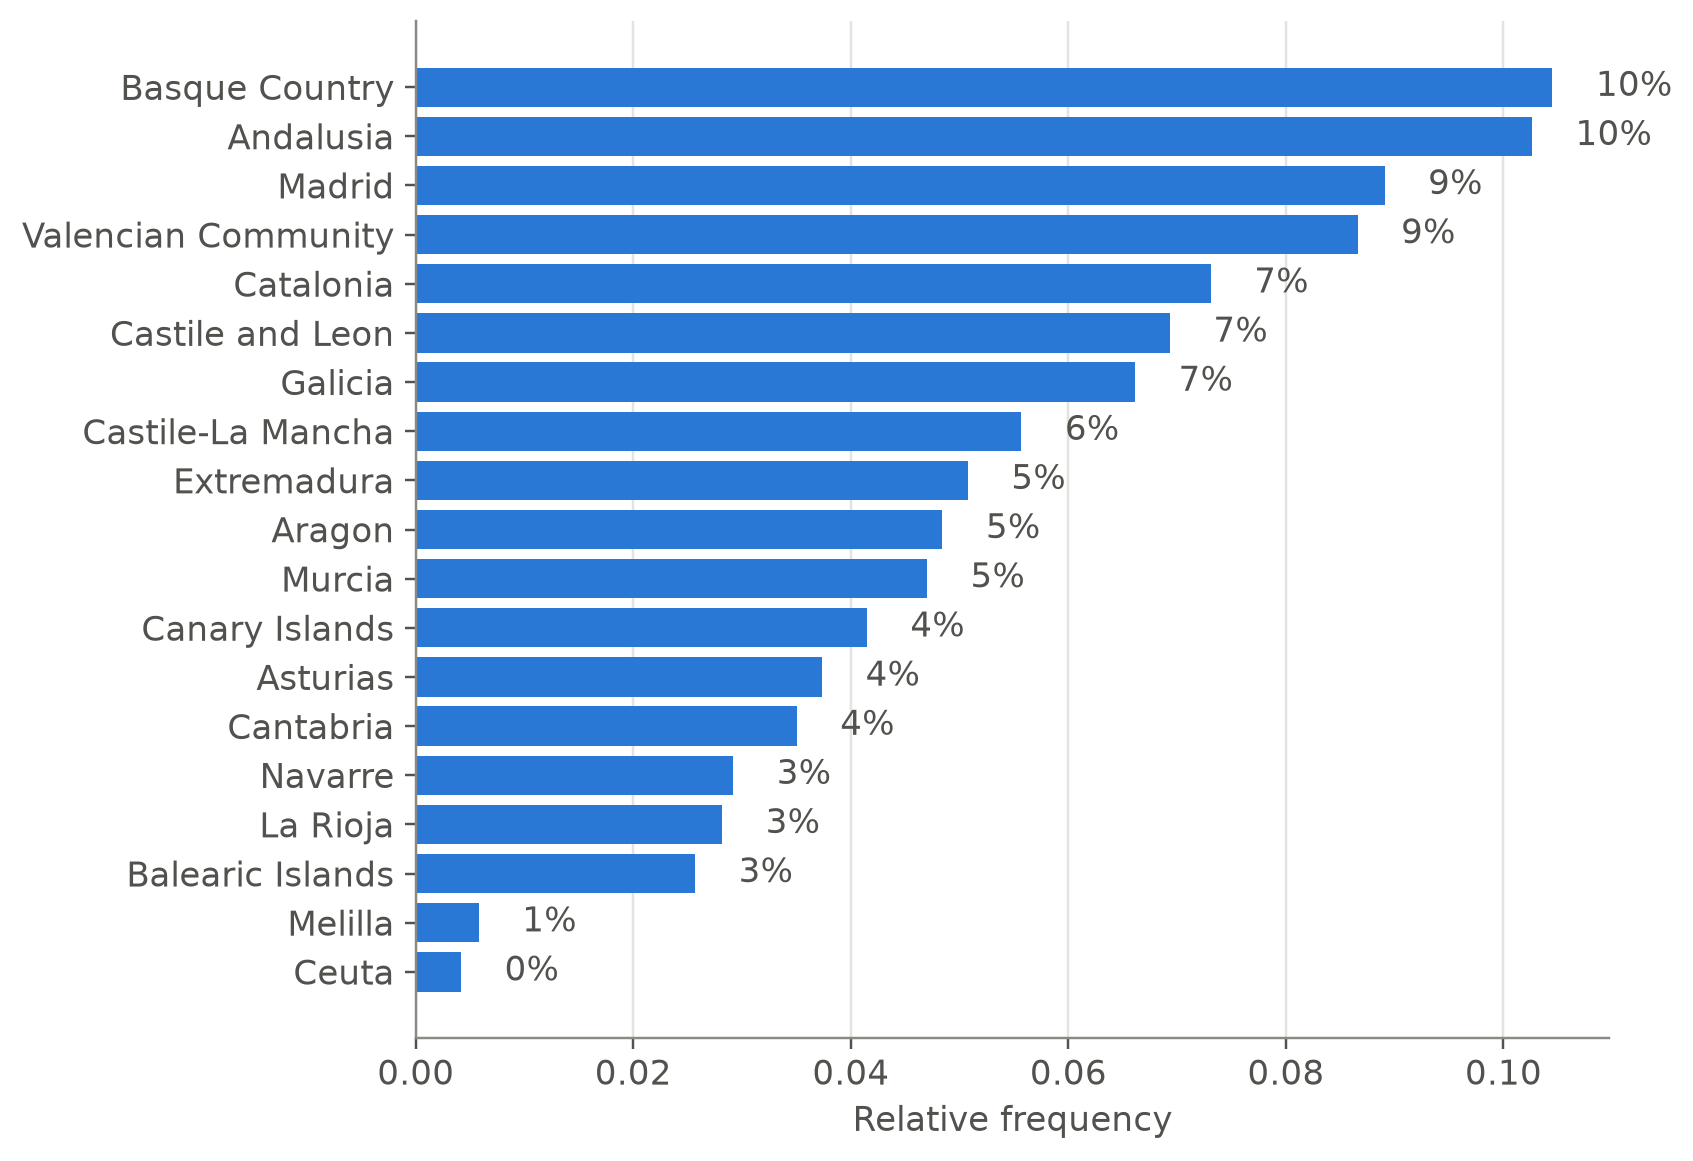

In [4]:
#| label: fig-bar-region
#| fig-cap: "Bar chart of the region of residence (relative frequencies)."
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(region_table["region"], region_table["f_i"], color=COLORS["blue"])
ax.invert_yaxis()  # most frequent category at the top
ax.set_xlabel("Relative frequency")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
for y, f in enumerate(region_table["f_i"]):
    ax.text(f + 0.004, y, f"{f:.0%}", va="center", color=COLORS["ink_soft"])
plt.show()

::: {.callout-warning}
## What about pie charts?

Pie charts are very popular, but we compare angles and areas much less
accurately than lengths along a common scale. This was shown experimentally by
@cleveland1984. With more than two or three categories, a bar chart conveys the
same information more precisely.
:::

::: {.callout-note}
## Historical note: the first bar and pie charts

Both graphs were invented by the Scottish engineer and economist William
Playfair. The bar chart appeared in his *Commercial and Political Atlas* (1786),
to show Scotland's imports and exports with its trading partners, because he
lacked the time series needed for a line chart. The pie chart appeared in his
*Statistical Breviary* (1801). Playfair is also credited with the first line
charts of economic time series.
:::

### Ordinal variables: cumulative frequencies

If the categories have a **natural order** (such as the education level of the
household's reference person), it makes sense to accumulate frequencies:

::: {.callout-note}
## Definition

- **Cumulative absolute frequency**: $N_i = n_1 + n_2 + \dots + n_i$.
- **Cumulative relative frequency**: $F_i = N_i / n = f_1 + \dots + f_i$.
:::

In Polars, the order of the categories is fixed with the `pl.Enum` type, so the
table follows the logical order instead of the alphabetical one:

In [5]:
education_order = pl.Enum(
    ["Below lower secondary", "Lower secondary", "Upper secondary", "Tertiary"]
)

education_table = (
    households
    .with_columns(pl.col("ref_education").cast(education_order))
    .group_by("ref_education")
    .agg(n_i=pl.len())
    .sort("ref_education")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(N_i=pl.col("n_i").cum_sum(), F_i=pl.col("f_i").cum_sum())
)
education_table

ref_education,n_i,f_i,N_i,F_i
Below lower secondary,2573,0.131,2573,0.131
Lower secondary,5134,0.261,7707,0.391
Upper secondary,4003,0.203,"11,710",0.594
Tertiary,7993,0.406,"19,703",1.000


For example, $F_3 \approx 0.59$ (third row of the table) is the proportion of
households whose reference person has at most upper secondary education.

## Quantitative data

### Discrete variables

A **discrete** variable takes few distinct values, such as the number of household
members. Its table is built as for an ordinal variable, sorting by value:

In [6]:
size_table = (
    households["household_size"]
    .value_counts(name="n_i")
    .sort("household_size")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(N_i=pl.col("n_i").cum_sum(), F_i=pl.col("f_i").cum_sum())
)
size_table

household_size,n_i,f_i,N_i,F_i
1,4612,0.234,4612,0.234
2,6438,0.327,"11,050",0.561
3,4287,0.218,"15,337",0.778
4,3411,0.173,"18,748",0.952
5,724,0.037,"19,472",0.988
6,173,0.009,"19,645",0.997
7,47,0.002,"19,692",0.999
8,6,0.000,"19,698",1.000
9,2,0.000,"19,700",1.000
10,1,0.000,"19,701",1.000


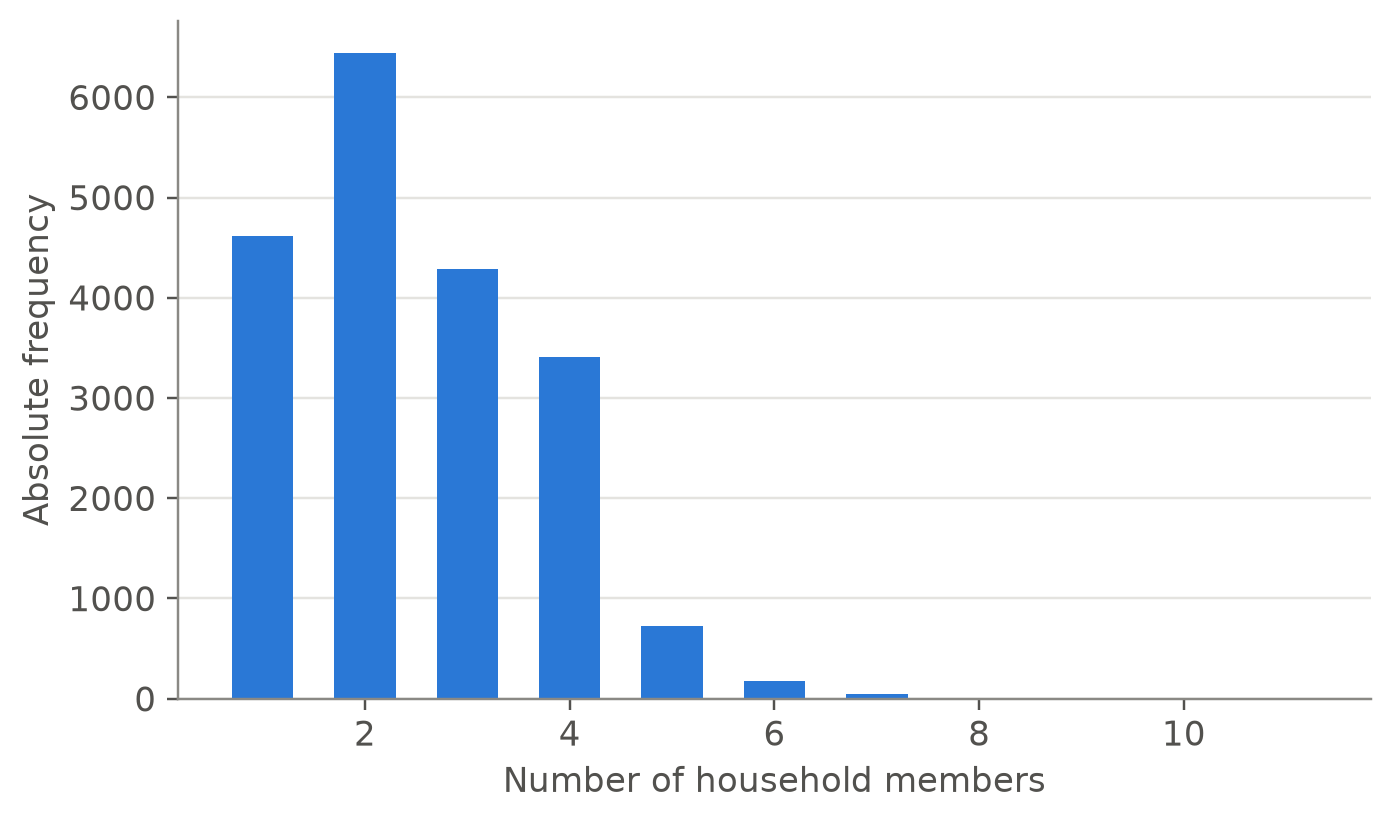

In [7]:
#| label: fig-bar-size
#| fig-cap: "Bar chart of household size."
fig, ax = plt.subplots()
ax.bar(size_table["household_size"], size_table["n_i"], width=0.6, color=COLORS["blue"])
ax.set_xlabel("Number of household members")
ax.set_ylabel("Absolute frequency")
plt.show()

### Continuous variables: grouping into classes

A **continuous** variable (income, expenditure) takes almost as many distinct
values as there are observations, so a table of individual values summarises
nothing. The data are grouped into **intervals or classes** $[L_{i-1}, L_i)$,
each with its **class mark** $x_i = (L_{i-1} + L_i)/2$ and its **width**
$a_i = L_i - L_{i-1}$.

In [8]:
#| label: tbl-expenditure-classes
#| tbl-cap: "Annual household expenditure grouped into classes of €10,000."
breaks = list(range(10_000, 100_001, 10_000))

expenditure_table = (
    households
    .with_columns(interval=pl.col("exp_total").cut(breaks, left_closed=True))
    .group_by("interval")
    .agg(n_i=pl.len())
    .sort("interval")
    .with_columns(f_i=pl.col("n_i") / pl.col("n_i").sum())
    .with_columns(F_i=pl.col("f_i").cum_sum())
)
expenditure_table

C:\Users\fscielzo\AppData\Local\Temp\ipykernel_3544\1068139498.py:5: DeprecationWarning: `cut` is deprecated; use `bin_intervals` instead
  .with_columns(interval=pl.col("exp_total").cut(breaks, left_closed=True))


interval,n_i,f_i,F_i
"[-inf, 10000)",464,0.024,0.024
"[10000, 20000)",3711,0.188,0.212
"[20000, 30000)",5159,0.262,0.474
"[30000, 40000)",4004,0.203,0.677
"[40000, 50000)",2652,0.135,0.812
"[50000, 60000)",1594,0.081,0.892
"[60000, 70000)",882,0.045,0.937
"[70000, 80000)",526,0.027,0.964
"[80000, 90000)",268,0.014,0.978
"[90000, 100000)",177,0.009,0.986


::: {.callout-tip}
## Polars detail

`cut()` creates intervals closed on the right, $(a, b]$, unless
`left_closed=True` is given, as here. The first and last intervals are open
($-\infty$ and $\infty$) so that all the data are included.
:::

### Histogram

The **histogram** is the graph of a grouped variable: each class is drawn as a
rectangle whose **area** is proportional to its frequency. With **density** on the
vertical axis, the height of rectangle $i$ is
$$
h_i = \frac{f_i}{a_i},
$$ {#eq-histogram-density}
and the total area of the histogram is 1. This is essential when the classes have
**different widths**.

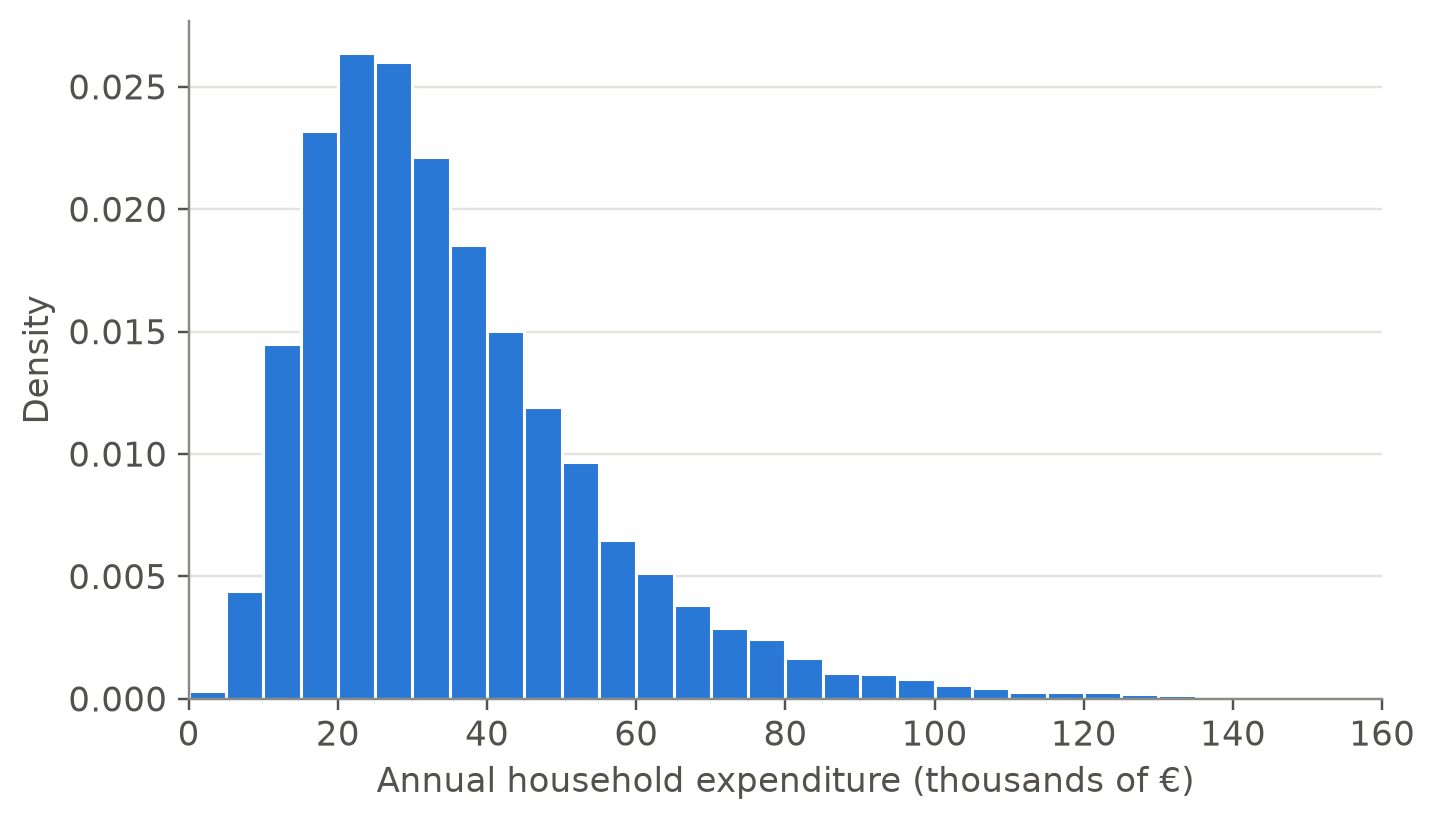

In [9]:
#| label: fig-hist-expenditure
#| fig-cap: "Histogram of annual household expenditure, in classes of €5,000. The horizontal axis is cut at €160,000: a few households lie further to the right."
expenditure = households["exp_total"].to_numpy()

fig, ax = plt.subplots()
ax.hist(expenditure / 1000, bins=np.arange(0, 335, 5), density=True,
        color=COLORS["blue"], edgecolor="white", linewidth=1)
ax.set_xlim(0, 160)
ax.set_xlabel("Annual household expenditure (thousands of €)")
ax.set_ylabel("Density")
plt.show()

@fig-hist-expenditure shows a **right-skewed** distribution: most households
spend between 15,000 and 45,000 € a year, and a few spend much more. This is the
typical shape of expenditure, income and wealth, but also of many health and
engineering variables (hospital stays, insurance claims, failure times).

::: {.callout-important}
## The number of classes matters

Too few classes hide the shape of the distribution; too many make it noisy. A
classical reference is **Sturges' rule**, $k \approx 1 + \log_2 n$
[@sturges1926], although in practice it is worth trying several values. Sturges'
rule tends to produce too few classes for large samples. Rules based on the
spread of the data, and the kernel density estimates of
[Topic 4](../04-distribution-estimation.qmd), address this problem.
:::

::: {.callout-note}
## Historical note: the word "histogram"

The term *histogram* was coined by Karl Pearson, who used it in his lectures in
the early 1890s and in print in 1895, in his work on skewed distributions
[@pearson1895]. Pearson was trying to describe biological and economic data whose
distributions, like the expenditure of @fig-hist-expenditure, were far from the
symmetric normal curve.
:::

## References {.unnumbered}

::: {#refs}
:::